# 07 · Exploração aprofundada | Retenção e movimentações, 2025

**Pergunta científica:** como se distribuem os desfechos do funil, quais mudanças efetivamente ocorreram entre M0 e M30, quais perfis aparecem entre retidos e qual a relação descritiva com os valores observados?

**Escopo:** junho–dezembro/2025, registros do funil, sem chave oficial do atendimento. **Dados de entrada:** `reports/extended_eda_2025.json` com resultados agregados de execução local da planilha autorizada. **Sem identificadores, linhas individuais ou ofertas observadas.**

> **Regra de interpretação:** `RETIDO` é um estado do funil; `FLAG_MOV_*` e trocas de produto não atestam aceite de oferta; deltas monetários entre M0 e M30 não medem lucro incremental. O que não é observável será tratado como cenário, não como achado.


## 1. Integridade e coortes: quem está sendo comparado?

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root/'pyproject.toml').exists(): root=root.parent
d=json.loads((root/'reports/extended_eda_2025.json').read_text(encoding='utf-8'))
co=d['counts']
print('População na janela:',f"{co['scope']:,}")
print('Registros retidos:',f"{co['retained']:,}")
print('Retidos com movimentação:',f"{co['retained_movement']:,}")
print('Cancelamentos parciais entre retidos:',f"{co['retained_cancellation']:,}")
assert co['status_RETIDO']==co['retained']
assert co['scope']==sum(co.get('status_'+x,0) for x in ('RETIDO','NAO RETIDO','LEAD EM ABERTO'))


População na janela: 303,652
Registros retidos: 249,309
Retidos com movimentação: 86,540
Cancelamentos parciais entre retidos: 45,479


### Casos abertos: limites, não sobrevida

Sem data individual do evento ou censura, Kaplan–Meier/Cox não são identificáveis. Porém é possível apresentar o intervalo entre dois cenários extremos: todos os casos abertos não retidos versus todos retidos. As duas linhas abaixo têm o mesmo denominador (todos os registros da coorte), diferentemente da retenção apenas entre encerrados.

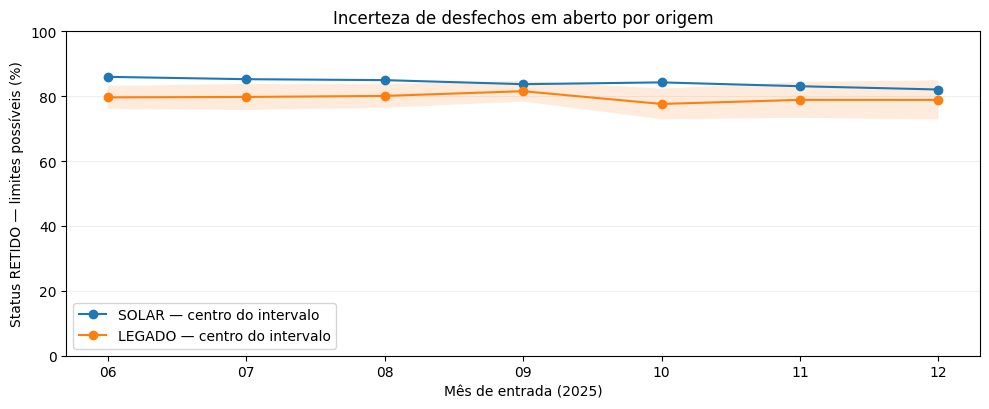

2025-06 LEGADO n= 9847 abertos= 696 limites= 76.1 83.2
2025-06 SOLAR n= 33371 abertos= 17 limites= 85.9 86.0
2025-07 LEGADO n= 8795 abertos= 706 limites= 75.8 83.8
2025-07 SOLAR n= 34449 abertos= 14 limites= 85.2 85.3
2025-08 LEGADO n= 8247 abertos= 604 limites= 76.4 83.8
2025-08 SOLAR n= 35171 abertos= 15 limites= 84.9 85.0
2025-09 LEGADO n= 8556 abertos= 547 limites= 78.4 84.7
2025-09 SOLAR n= 34914 abertos= 5 limites= 83.7 83.7
2025-10 LEGADO n= 9652 abertos= 911 limites= 72.9 82.3
2025-10 SOLAR n= 33857 abertos= 11 limites= 84.2 84.3
2025-11 LEGADO n= 11142 abertos= 1234 limites= 73.3 84.4
2025-11 SOLAR n= 32195 abertos= 14 limites= 83.1 83.1
2025-12 LEGADO n= 12141 abertos= 1464 limites= 72.8 84.9
2025-12 SOLAR n= 31315 abertos= 14 limites= 82.0 82.1


In [2]:
coh=d['retention_bounds_by_month_origin']
fig,ax=plt.subplots(figsize=(10,4.2))
for origin in ['SOLAR','LEGADO']:
    a=sorted([r for r in coh if r['origin']==origin],key=lambda r:r['month'])
    labels=[r['month'][-2:] for r in a]
    lo=np.array([r['lower_if_all_open_not_retained'] for r in a])*100
    hi=np.array([r['upper_if_all_open_retained'] for r in a])*100
    ax.plot(labels, (lo+hi)/2,marker='o', label=f'{origin} — centro do intervalo')
    ax.fill_between(labels, lo,hi,alpha=.15)
ax.set(ylabel='Status RETIDO — limites possíveis (%)',xlabel='Mês de entrada (2025)',title='Incerteza de desfechos em aberto por origem')
ax.set_ylim(0,100);ax.legend();ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()
for x in coh: print(x['month'],x['origin'], 'n=',x['n'],'abertos=',x['opened'], 'limites=',round(x['lower_if_all_open_not_retained']*100,1),round(x['upper_if_all_open_retained']*100,1))


## 2. Perfil das movimentações: famílias e transições efetivas

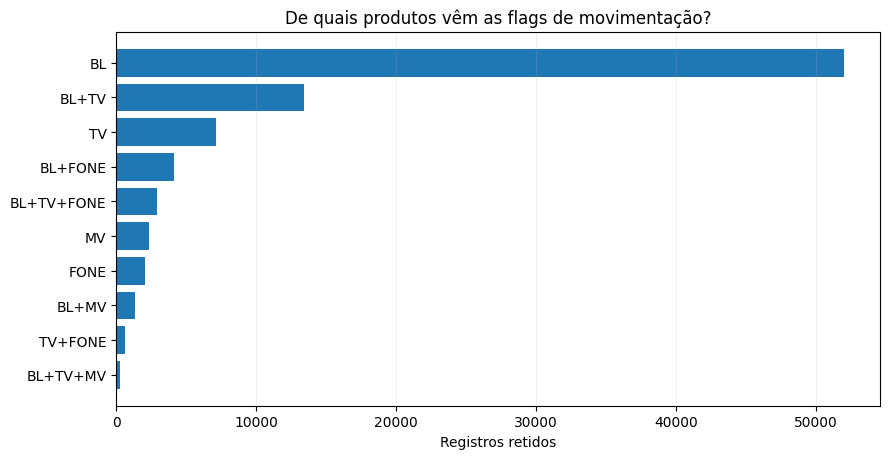

Combinações de movimentação e denominador: retidos, independentemente de cancelamento
BL                   51,962 — 60.0% dos retidos movimentados
BL+TV                13,404 — 15.5% dos retidos movimentados
TV                    7,091 — 8.2% dos retidos movimentados
BL+FONE               4,125 — 4.8% dos retidos movimentados
BL+TV+FONE            2,906 — 3.4% dos retidos movimentados
MV                    2,355 — 2.7% dos retidos movimentados
FONE                  2,023 — 2.3% dos retidos movimentados
BL+MV                 1,315 — 1.5% dos retidos movimentados
TV+FONE                 642 — 0.7% dos retidos movimentados
BL+TV+MV                282 — 0.3% dos retidos movimentados


In [3]:
mov=d['movement_combinations_retained']
leader=[(name,n) for name,n in mov.items() if name!='NONE'][:10]
fig,ax=plt.subplots(figsize=(9,4.7))
ax.barh([name for name,n in leader][::-1],[n for name,n in leader][::-1]);ax.set(xlabel='Registros retidos',title='De quais produtos vêm as flags de movimentação?')
ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()
print('Combinações de movimentação e denominador: retidos, independentemente de cancelamento')
for k,v in leader:print(f'{k:17s} {v:>9,} — {v/co["retained_movement"]:.1%} dos retidos movimentados')


### Anatomia de M0 → M30

As classes são transições do *código de produto por família*: `replacement`, `removal`, `addition`, `unchanged`, `absent`. **Não são tipos de oferta.** Flag de movimentação e flag de cancelamento permanecem indicadores distintos.


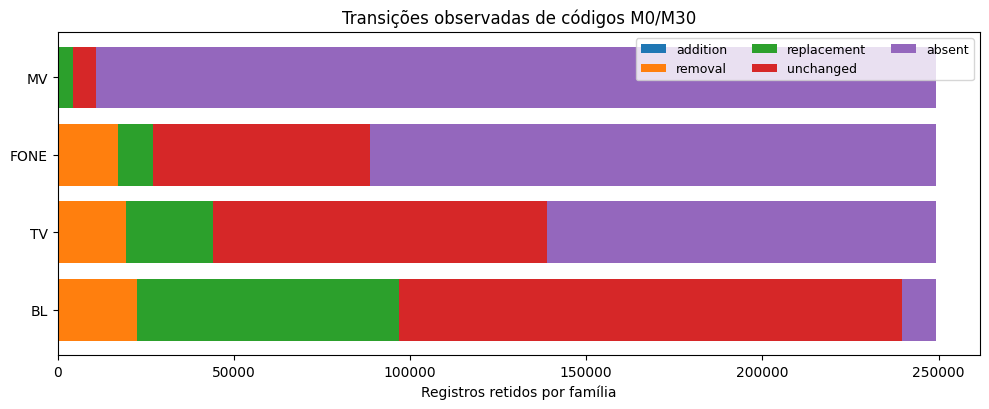

BL {'addition': 0, 'removal': 22478, 'replacement': 74255, 'unchanged': 142829, 'absent': 9747}
TV {'addition': 0, 'removal': 19381, 'replacement': 24595, 'unchanged': 94778, 'absent': 110555}
FONE {'addition': 0, 'removal': 17059, 'replacement': 10007, 'unchanged': 61512, 'absent': 160731}
MV {'addition': 0, 'removal': 0, 'replacement': 4387, 'unchanged': 6577, 'absent': 238345}


In [4]:
families=['BL','TV','FONE','MV'];states=['addition','removal','replacement','unchanged','absent']
a=np.array([[d['product_transition_economics_retained'].get(f,{}).get(s,{}).get('n',0) for s in states] for f in families])
fig,ax=plt.subplots(figsize=(10,4.2))
left=np.zeros(len(families))
for state,values in zip(states,a.T):
  ax.barh(families, values,left=left,label=state);left+=values
ax.set(xlabel='Registros retidos por família',title='Transições observadas de códigos M0/M30')
ax.legend(ncol=3,fontsize=9);plt.tight_layout();plt.show()
for f,values in zip(families,a):print(f,dict(zip(states,values.tolist())))


## 3. Mudança monetária: onde ocorre a redução observada?

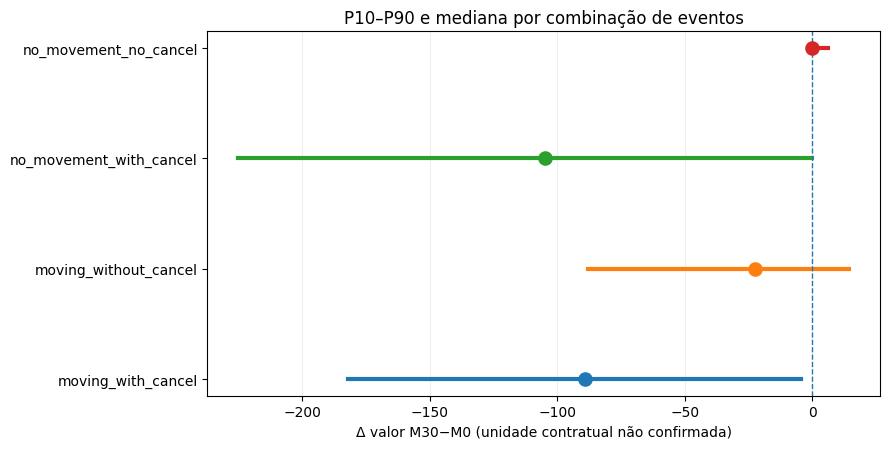

moving_with_cancel n= 13161 mediana= -88.96 negativos= 91.0 %
moving_without_cancel n= 73379 mediana= -22.48 negativos= 76.5 %
no_movement_with_cancel n= 32318 mediana= -104.9 negativos= 81.1 %
no_movement_no_cancel n= 130451 mediana= 0.0 negativos= 4.3 %


In [5]:
groups=['moving_with_cancel','moving_without_cancel','no_movement_with_cancel','no_movement_no_cancel']
existing=[g for g in groups if g in d['retained_value_distributions']]
rows=[d['retained_value_distributions'][g] for g in existing]
fig,ax=plt.subplots(figsize=(9,4.6))
for i,(key,entry) in enumerate(zip(existing,rows)):
  ax.plot([entry['p10_delta'],entry['p90_delta']],[i,i],linewidth=3)
  ax.scatter([entry['median_delta']],[i],s=90,zorder=3)
ax.axvline(0,linewidth=1,linestyle='--')
ax.set_yticks(range(len(existing)),existing)
ax.set(xlabel='Δ valor M30−M0 (unidade contratual não confirmada)',title='P10–P90 e mediana por combinação de eventos')
ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()
for key,entry in zip(existing,rows):
 print(key,'n=',entry['n'],'mediana=',round(entry['median_delta'],2),'negativos=',round(entry['negative']*100,1),'%')


### Produto e tipo de alteração

A comparação por produto usa apenas pares M0/M30 com ambos os campos numéricos. Mudanças de preços e descontos podem ocorrer sem mudança de código; cancelamentos de Fone podem ter valor zero, tornando perigosa qualquer interpretação contábil direta.


In [6]:
tab=d['product_transition_economics_retained']
for fam in families:
 print('\n',fam)
 for state in ('replacement','removal','unchanged','addition'):
  r=tab.get(fam,{}).get(state)
  if r:print(f"  {state:<12}: n={r['n']:>7,}; Δ médio={r['average_delta_priced']:>9.2f}; % Δ negativo={r['negative_share_priced']:.1%}")



 BL
  replacement : n= 74,255; Δ médio=   -22.08; % Δ negativo=80.0%
  removal     : n= 22,478; Δ médio=  -101.32; % Δ negativo=96.3%
  unchanged   : n=142,829; Δ médio=     0.98; % Δ negativo=1.2%

 TV
  replacement : n= 24,595; Δ médio=   -30.76; % Δ negativo=74.4%
  removal     : n= 19,381; Δ médio=  -118.33; % Δ negativo=97.8%
  unchanged   : n= 94,778; Δ médio=     1.46; % Δ negativo=8.0%

 FONE
  replacement : n= 10,007; Δ médio=     0.00; % Δ negativo=0.0%
  removal     : n= 17,059; Δ médio=     0.00; % Δ negativo=0.0%
  unchanged   : n= 61,512; Δ médio=     0.00; % Δ negativo=0.0%

 MV
  replacement : n=  4,387; Δ médio=    -4.81; % Δ negativo=53.9%
  unchanged   : n=  6,577; Δ médio=    -1.64; % Δ negativo=4.3%


## 4. Origem: diferença bruta e diferença padronizada

In [7]:
g=d['channel_comparison_standardized']
if g.get('identified'):
 print('Diferença SOLAR − LEGADO, bruta: ',f"{g['raw_solar_minus_legado']*100:.2f} pontos percentuais")
 print('Diferença padronizada por mês × famílias M0: ',f"{g['standardized_solar_minus_legado']*100:.2f} pontos percentuais")
 print('IC 95% por bootstrap de clientes (200 réplicas): ',[round(v*100,2) for v in g['ci_95_cluster_poisson']],'p.p.')
 print('Cobertura do suporte comum: ',f"{g['common_support_coverage']:.1%}")
 print('Clientes usados na clusterização:',f"{g['unique_clients_clustered']:,}")
else:print('Estimativa padronizada não identificada na amostra')


Diferença SOLAR − LEGADO, bruta:  3.41 pontos percentuais
Diferença padronizada por mês × famílias M0:  2.93 pontos percentuais
IC 95% por bootstrap de clientes (200 réplicas):  [2.53, 3.41] p.p.
Cobertura do suporte comum:  99.8%
Clientes usados na clusterização: 235,462


**Interpretação:** padronização ajusta apenas o mix de famílias e mês entre registros **já retidos**; não corrige seleção de origem, atributos omitidos, desfechos em aberto ou causa. O intervalo captura parte da dependência de múltiplos registros por cliente; não é intervalo de efeito causal.

## 5. Critério econômico de decisão: análise paramétrica, não lucro estimado

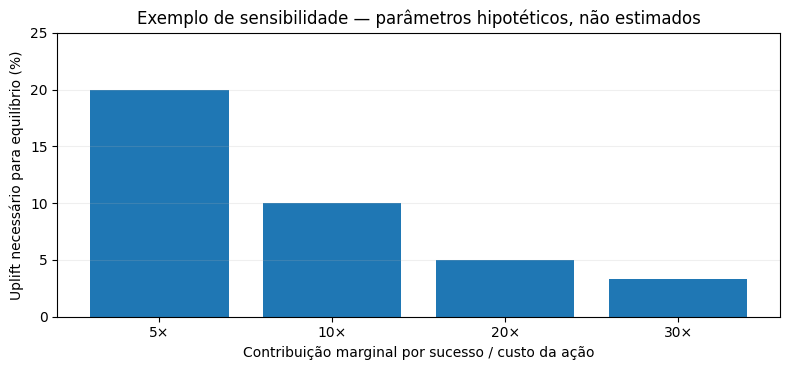

Nenhum parâmetro desta figura foi estimado na planilha do case.


In [8]:
# Exemplo adimensional inspirado na seleção por lucro: u_min = custo por ação / contribuição marginal por sucesso incremental.
# A razão contribuição/custo e uplift são HIPÓTESES, não dados da empresa.
ratios=np.array([5,10,20,30],dtype=float)
threshold=1/ratios
fig,ax=plt.subplots(figsize=(8,3.8))
ax.bar([f'{int(x)}×' for x in ratios],threshold*100)
ax.set(ylabel='Uplift necessário para equilíbrio (%)',xlabel='Contribuição marginal por sucesso / custo da ação',
       title='Exemplo de sensibilidade — parâmetros hipotéticos, não estimados')
ax.set_ylim(0,25);ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
print('Nenhum parâmetro desta figura foi estimado na planilha do case.')


## 6. O que **não** pode ser estimado, e qual informação permitiria

- **Lucro incremental observado:** exige custo/valor da intervenção, margem de contribuição, horizonte e contrafactual. Os snapshots M0/M30 servem apenas à análise descritiva de variação de valor.
- **Uplift de oferta:** exige tratamento/controle, oferta elegível e atribuída, aceitação e outcome comparável após a ação. O campo `FLAG_ORIGEM` não é randomização de oferta.
- **Sobrevivência do relacionamento:** exige início da observação, tempo até cancelamento, censura e acompanhamento posterior. Data de entrada no funil mais dois snapshots M0/M30 não fornecem tempos de evento.
- **Intervalos e contrastes descritivos:** estes **são** calculáveis, inclusive por cluster de cliente. Ainda não corrigem confundimento ou seleção.

**Conclusão:** a exploração analítica pode ser aprofundada e testada com a base recebida, mas nenhum algoritmo transforma ausência de informação causal ou temporal em evidência observada. Consulte `docs/study_report.md` e `docs/benchmark_and_gap_review.md` para as definições completas.